In [6]:
import pandas as pd

# Wczytanie danych
df = pd.read_csv("diabetes_large_dataset.csv")

# Rozmiar danych
print("Rozmiar danych:", df.shape)
print("Liczba obserwacji:", df.shape[0])
print("Liczba zmiennych:", df.shape[1])

# Typy zmiennych
print("\nTypy zmiennych:")
print(df.dtypes)

# Braki danych we wszystkich zmiennych
print("\nLiczba braków:")
print(df.isna().sum().sort_values(ascending=False))

# Liczba unikalnych wartości we wszystkich zmiennych
print("\nLiczba wartości unikalnych:")
print(df.nunique(dropna=False).sort_values())

# Unikalne wartości tylko dla zmiennych nieliczbowych
print("\nUnikalne wartości zmiennych nieliczbowych:")

kolumny_nieliczbowe = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for kolumna in kolumny_nieliczbowe:
    print(f"\n{kolumna}:")
    print(df[kolumna].value_counts(dropna=False).head(30))

Rozmiar danych: (100000, 209)
Liczba obserwacji: 100000
Liczba zmiennych: 209

Typy zmiennych:
patient_id                     str
record_id                      str
age                        float64
age_group                      str
sex                            str
                            ...   
chronic_condition_count      int64
hospitalization_history        str
emergency_visit_history        str
diabetes_status            float64
diabetes_type                  str
Length: 209, dtype: object

Liczba braków:
age_at_menopause                82257
fasting_insulin_uIU_ml          10178
self_management_score           10177
urine_albumin_mg_g              10134
medication_adherence_percent    10054
                                ...  
mental_wellbeing_score              0
chronic_condition_count             0
quality_of_life_score               0
emergency_visit_history             0
hospitalization_history             0
Length: 209, dtype: int64

Liczba wartości unikalnych:
prot

C:\Users\micha\AppData\Local\Temp\ipykernel_13932\3208954839.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolumny_nieliczbowe = df.select_dtypes(


smoking_frequency
Never            54848
Not Currently    25007
Daily            12165
Occasionally      5048
Socially          2932
Name: count, dtype: int64

alcohol_use:
alcohol_use
Yes    56911
No     38108
NaN     4981
Name: count, dtype: int64

alcohol_frequency:
alcohol_frequency
Never           40151
Weekly          20721
Occasionally    18123
Monthly         15042
Daily            5963
Name: count, dtype: int64

physical_activity_level:
physical_activity_level
Lightly Active       28448
Sedentary            23839
Moderately Active    23699
Very Active          14262
NaN                   5007
Extremely Active      4745
Name: count, dtype: int64

sleep_quality:
sleep_quality
Good         39856
Fair         29898
Poor         15132
Excellent    15114
Name: count, dtype: int64

stress_level:
stress_level
Moderate     38038
Low          23852
High         23731
Very High     9486
NaN           4893
Name: count, dtype: int64

processed_food_frequency:
processed_food_frequency
Somet

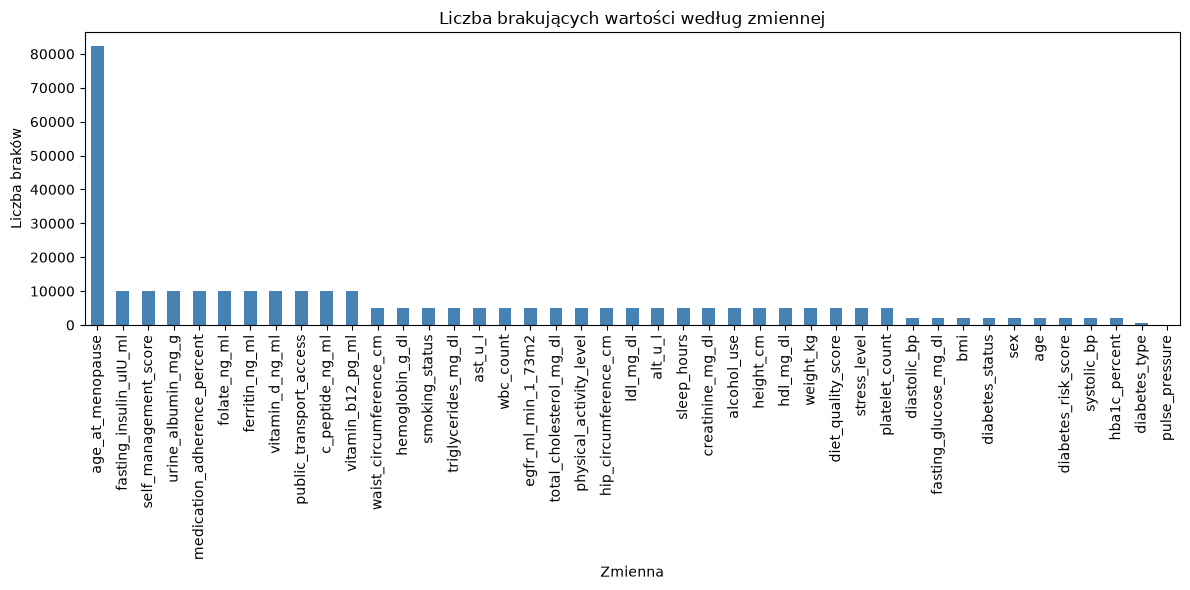

In [7]:
import matplotlib.pyplot as plt

# Liczba braków w każdej kolumnie
braki = df.isna().sum()

# Zostawiamy tylko kolumny, w których występują braki
braki = braki[braki > 0].sort_values(ascending=False)

# Wykres
plt.figure(figsize=(12, 6))
braki.plot(kind="bar", color="steelblue")

plt.title("Liczba brakujących wartości według zmiennej")
plt.xlabel("Zmienna")
plt.ylabel("Liczba braków")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

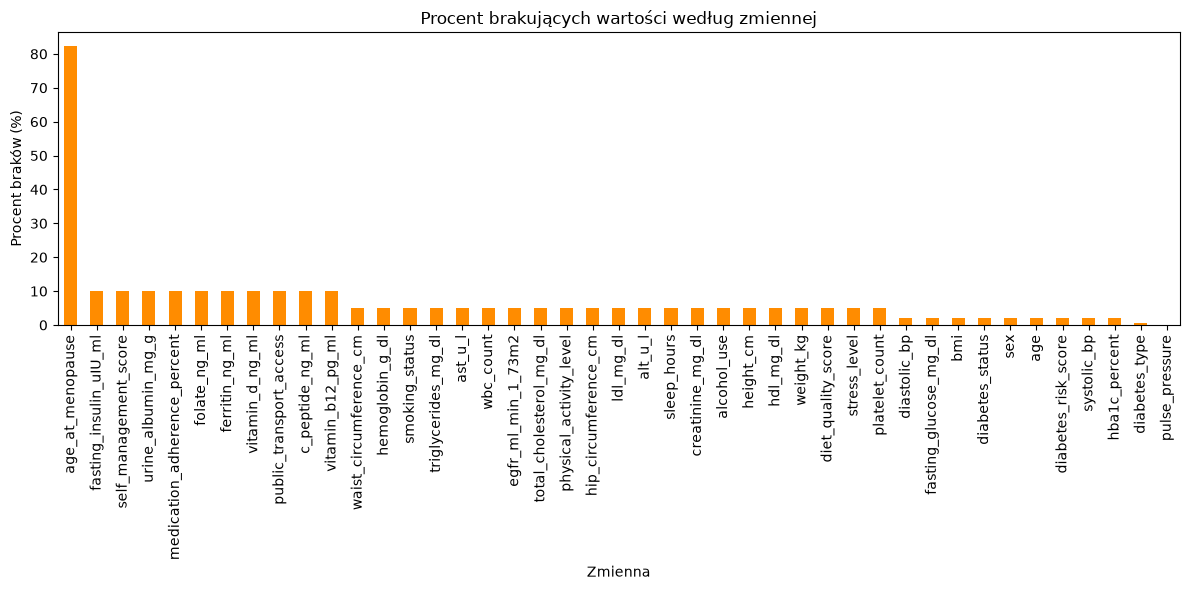

In [8]:
procent_brakow = (df.isna().mean() * 100)
procent_brakow = procent_brakow[procent_brakow > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
procent_brakow.plot(kind="bar", color="darkorange")

plt.title("Procent brakujących wartości według zmiennej")
plt.xlabel("Zmienna")
plt.ylabel("Procent braków (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
df['age'].unique()

array([57., 47., 59., 72., 46., 73., 61., 42., 58., 43., 53., 21., 24.,
       41., 34., 54., 36., 28., 71., 51., 32., 55., 40., 45., 77., 49.,
       62., nan, 20., 30., 52., 48., 27., 39., 65., 23., 44., 63., 37.,
       64., 33., 18., 50., 56., 78., 86., 67., 82., 35., 26., 38., 31.,
       69., 25., 90., 60., 66., 29., 84., 19., 76., 81., 74., 68., 80.,
       70., 79., 75., 88., 22., 89., 87., 83., 85.])

In [10]:
df['diet_quality_score'].unique()

array([ 53.4,  53.6,   nan,  67.5,  52.8,  69.6,  40.7,  66.3,  52. ,
        58.1,  48. ,  74.8,  33.7,  59.6,  46. ,  64.3,  58.7,  42.3,
        44.2,  44.9,  59.1,  30.9,  47.6,  31.8,  84.4,  79. ,  60.9,
        54.6,  41. ,  60.7,  41.9,  46.8,  89.2,  44.3,  41.1,  70.3,
        73.7,  44. ,  43.4,  64.7,  68.5,  67.4,  61.5,  58.2,  42.5,
        72.6,  44.7,  46.1,  67.1,  55.1,  63.6,  64.8,  43.7,  66.2,
        57.1,  69.3,  64.1,  53.5,  36.5,  54.3,  62.2,  45.1,  52.9,
        53.2,  42.8,  75.8,  40.3,  56.5,  88.9,  56.7,  60.6,  69.5,
        45.8,  80.9,  59.7,  74.6,  71.6,  56.9,  52.3,  63.5,  41.5,
        55.6,  67.8,  64.2,  62.1,  57.8,  49.8,  33.2,  77. ,  54.5,
        58.3,  43.9,  73.1,  92.2,  59.2,  38.4,  58. ,  65.6,  58.5,
        46.4,  37. ,  63.9,  39.6,  25.4,  78.8,  77.6,  48.8,  77.3,
        86. ,  66.6,  54.8,  45.6,  51.8,  58.9,  55.5,  59.5,  21.7,
        49.2,  30. ,  76.8,  75. ,  35.2,  65.2,  59.8,  54.2,  25.8,
        56.1,  77.2,